# Pandemic mobility control: PI, PID and DQN + PI

Original working notebook, kept with its saved outputs.

- **First code cells:** first version. Compares lockdown, no policy, a manual threshold and a dynamic PI controller (with a sweep over its gain k and look-ahead).
- **DQN + PI v3:** adds a PID baseline, trains a dueling double DQN (prioritised replay, 10-step returns, replay pre-filled with PI/PID episodes) that adjusts the PI controller's output, and compares all policies.
- **Last cells:** save the model to `saved_models/dqn_pi_v3.pth`, reload it and evaluate it.

Known issue in this notebook: in the ensemble rows of the results table the efficiency is computed from the per-day mobility array instead of its total, so it prints 0.0001. `pandemic_sim.py` fixes this, and `evaluate.py` re-evaluates the saved model on fixed seeds. Training takes roughly 30 minutes on a CPU.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.spatial.distance import cdist

# --- 1. GLOBAL PARAMETERS ---
NUM_AGENTS = 2500
GRID_SIZE = 1.0
DAYS = 200
CAPACITY_LIMIT = 500

R_AVG = 1.0 / np.sqrt(NUM_AGENTS)
INF_RADIUS = R_AVG / 5.0
INF_RADIUS_SQ = INF_RADIUS ** 2

L_LOCKDOWN = 0.016
L_OPEN = 2.0 * R_AVG  # ~0.04


# --- 2. FAST INFECTION (GRID BUCKETING) ---
def infect_grid(positions, status, inf_radius_sq, grid_size=20):
    """Grid-bucketed infection check — O(N) instead of O(N^2)."""
    G = grid_size
    cells = [[] for _ in range(G * G)]
    inf_cells = [[] for _ in range(G * G)]

    for i in range(len(positions)):
        gx = min(G - 1, int(positions[i, 0] * G))
        gy = min(G - 1, int(positions[i, 1] * G))
        idx = gy * G + gx

        if status[i] == 1:
            inf_cells[idx].append(i)
        else:
            cells[idx].append(i)

    new_infected = []

    for cy in range(G):
        for cx in range(G):
            sus = cells[cy * G + cx]
            if not sus:
                continue

            for dy in range(-1, 2):
                for dx in range(-1, 2):
                    ny, nx = cy + dy, cx + dx

                    if ny < 0 or ny >= G or nx < 0 or nx >= G:
                        continue

                    infs = inf_cells[ny * G + nx]
                    if not infs:
                        continue

                    for si in sus:
                        if status[si] == 1:
                            continue

                        for ii in infs:
                            d2 = (
                                (positions[si, 0] - positions[ii, 0]) ** 2
                                + (positions[si, 1] - positions[ii, 1]) ** 2
                            )
                            if d2 <= inf_radius_sq:
                                new_infected.append(si)
                                break

    for si in new_infected:
        status[si] = 1


# --- 3. MOVEMENT WITH REFLECTIVE BOUNDARIES ---
def move_agents(positions, l):
    angles = np.random.uniform(0, 2 * np.pi, len(positions))
    positions[:, 0] += l * np.cos(angles)
    positions[:, 1] += l * np.sin(angles)

    # Reflective boundaries
    positions[:] = np.abs(positions)
    positions[:] = np.where(
        positions > GRID_SIZE, 2 * GRID_SIZE - positions, positions
    )


# --- 4. BASELINE SIMULATION ---
def run_baseline(policy_type="lockdown"):
    positions = np.random.rand(NUM_AGENTS, 2)
    status = np.zeros(NUM_AGENTS, dtype=np.uint8)

    status[np.argmin(cdist(positions, [[0.5, 0.5]]))] = 1

    history = []
    mobility = []

    for day in range(DAYS):
        current_inf = int(np.sum(status))

        if policy_type == "lockdown":
            l = L_LOCKDOWN
        elif policy_type == "none":
            l = L_OPEN
        elif policy_type == "manual":
            l = (
                L_LOCKDOWN
                if current_inf > (0.8 * CAPACITY_LIMIT)
                else L_OPEN
            )
        else:
            raise ValueError(f"Unknown policy: {policy_type}")

        mobility.append(l)

        move_agents(positions, l)
        infect_grid(positions, status, INF_RADIUS_SQ)

        history.append(current_inf)

    return np.array(history), np.array(mobility)


# --- 5. DYNAMIC CONTROLLER ---
def run_dynamic(k=6, look_ahead=3):
    positions = np.random.rand(NUM_AGENTS, 2)
    status = np.zeros(NUM_AGENTS, dtype=np.uint8)

    status[np.argmin(cdist(positions, [[0.5, 0.5]]))] = 1

    history = []
    mobility = []

    prev_l = L_OPEN
    integral = 0.0
    recent_inf = []

    for day in range(DAYS):
        current_inf = int(np.sum(status))

        recent_inf.append(current_inf)
        if len(recent_inf) > look_ahead + 1:
            recent_inf.pop(0)

        cap_ratio = current_inf / CAPACITY_LIMIT

        # Trend
        trend = 0.0
        if len(recent_inf) >= 2:
            trend = (
                (recent_inf[-1] - recent_inf[0])
                / (len(recent_inf) - 1)
                / CAPACITY_LIMIT
            )

        # Integral
        if cap_ratio > 1.0:
            integral = min(integral + (cap_ratio - 1.0) * 0.05, 1.0)
        else:
            integral = max(0.0, integral - 0.01)

        # Prediction
        predictive = cap_ratio + look_ahead * max(0.0, trend)

        # Control zones
        if predictive < 0.3:
            target_l = L_OPEN

        elif predictive < 0.8:
            t = (predictive - 0.3) / 0.5
            target_l = L_OPEN * np.exp(-k * t)

        else:
            target_l = L_OPEN * np.exp(-k) * np.exp(-k * integral)

        # Hysteresis
        hyst_threshold = 0.6 if prev_l < L_OPEN * 0.5 else 1.0
        if cap_ratio > hyst_threshold * 0.8:
            target_l = min(target_l, prev_l)

        # Rate limiting
        max_delta = 0.15 * L_OPEN
        l = np.clip(target_l, prev_l - max_delta, prev_l + max_delta)

        l = float(np.clip(l, L_LOCKDOWN * 0.5, L_OPEN))
        prev_l = l

        mobility.append(l)

        move_agents(positions, l)
        infect_grid(positions, status, INF_RADIUS_SQ)

        history.append(current_inf)

    return np.array(history), np.array(mobility)


# --- 6. METRICS ---
def calculate_metrics(history, mobility):
    peak = int(np.max(history))
    total_mobility = float(np.sum(mobility))
    days_over = int(np.sum(history > CAPACITY_LIMIT))
    total_inf = float(np.sum(history))

    efficiency = total_mobility / (total_inf / 1000 + 1e-9)

    return {
        "Peak": peak,
        "Mobility": round(total_mobility, 2),
        "Days Over Cap": days_over,
        "Efficiency": round(efficiency, 4),
    }


# --- 7. PARAMETER SWEEP ---
def sweep_dynamic(k_values=None, look_ahead_values=None):

    if k_values is None:
        k_values = [2, 4, 6, 8, 10]

    if look_ahead_values is None:
        look_ahead_values = [1, 3, 5]

    best_k, best_la = None, None
    best_score = float("inf")
    best_result = None

    print("\n--- Dynamic Controller Sweep ---")
    print(f"{'k':>4} {'look_ahead':>10} {'Peak':>6} {'DaysOver':>9} {'Mobility':>10} {'Score':>8}")
    print("-" * 55)

    for k in k_values:
        for la in look_ahead_values:

            h, m = run_dynamic(k=k, look_ahead=la)
            metrics = calculate_metrics(h, m)

            score = metrics["Peak"] + 5 * metrics["Days Over Cap"]

            print(
                f"{k:>4} {la:>10} {metrics['Peak']:>6} "
                f"{metrics['Days Over Cap']:>9} "
                f"{metrics['Mobility']:>10.2f} {score:>8}"
            )

            if score < best_score:
                best_score = score
                best_k = k
                best_la = la
                best_result = (h, m, metrics)

    print(f"\nBest config: k={best_k}, look_ahead={best_la}  (score={best_score})")

    return best_k, best_la, best_result


# --- 8. RUN SCENARIOS ---
print("Running baseline scenarios...")
data = {}

for s in ["lockdown", "none", "manual"]:
    print(f"  {s}...", end="", flush=True)

    h, m = run_baseline(s)
    data[s] = {
        "history": h,
        "mobility": m,
        "metrics": calculate_metrics(h, m),
    }

    print(" done")

print("\nRunning dynamic controller sweep...")

best_k, best_la, best_result = sweep_dynamic()

data["dynamic"] = {
    "history": best_result[0],
    "mobility": best_result[1],
    "metrics": best_result[2],
}


# --- 9. RESULTS TABLE ---
print(f"\n{'Policy':<15} | {'Peak':>6} | {'Mobility':>10} | {'Days Over Cap':>13} | {'Efficiency':>10}")
print("-" * 70)

for key in ["lockdown", "none", "manual", "dynamic"]:
    m = data[key]["metrics"]

    print(
        f"{key:<15} | {m['Peak']:>6} | {m['Mobility']:>10.2f} | "
        f"{m['Days Over Cap']:>13} | {m['Efficiency']:>10.4f}"
    )


# --- 10. COMPARISON ---
dyn_mob = data["dynamic"]["metrics"]["Mobility"]
lock_mob = data["lockdown"]["metrics"]["Mobility"]

gain_pct = (dyn_mob - lock_mob) / lock_mob * 100

peak_reduction = (
    (data["none"]["metrics"]["Peak"] - data["dynamic"]["metrics"]["Peak"])
    / data["none"]["metrics"]["Peak"]
    * 100
)

print(f"\nDynamic vs Lockdown  → +{gain_pct:.1f}% more mobility")
print(f"Dynamic vs No Policy → {peak_reduction:.1f}% lower peak infections")

Running baseline scenarios...
  lockdown... done
  none... done
  manual... done

Running dynamic controller sweep...

--- Dynamic Controller Sweep ---
   k look_ahead   Peak  DaysOver   Mobility    Score
-------------------------------------------------------
   2          1   2115       140       2.92     2815
   2          3   2121       139       3.02     2816
   2          5   1911       119       3.61     2506
   4          1   1912       134       2.96     2582
   4          3   2273       140       2.96     2973
   4          5   2195       137       2.90     2880
   6          1   1900       134       3.08     2570
   6          3   2153       133       3.10     2818
   6          5   1747       129       3.05     2392
   8          1   1765       127       3.31     2400
   8          3   1765       143       2.76     2480
   8          5   1835       114       3.49     2405
  10          1   1826       102       4.26     2336
  10          3   1793       121       3.40     23

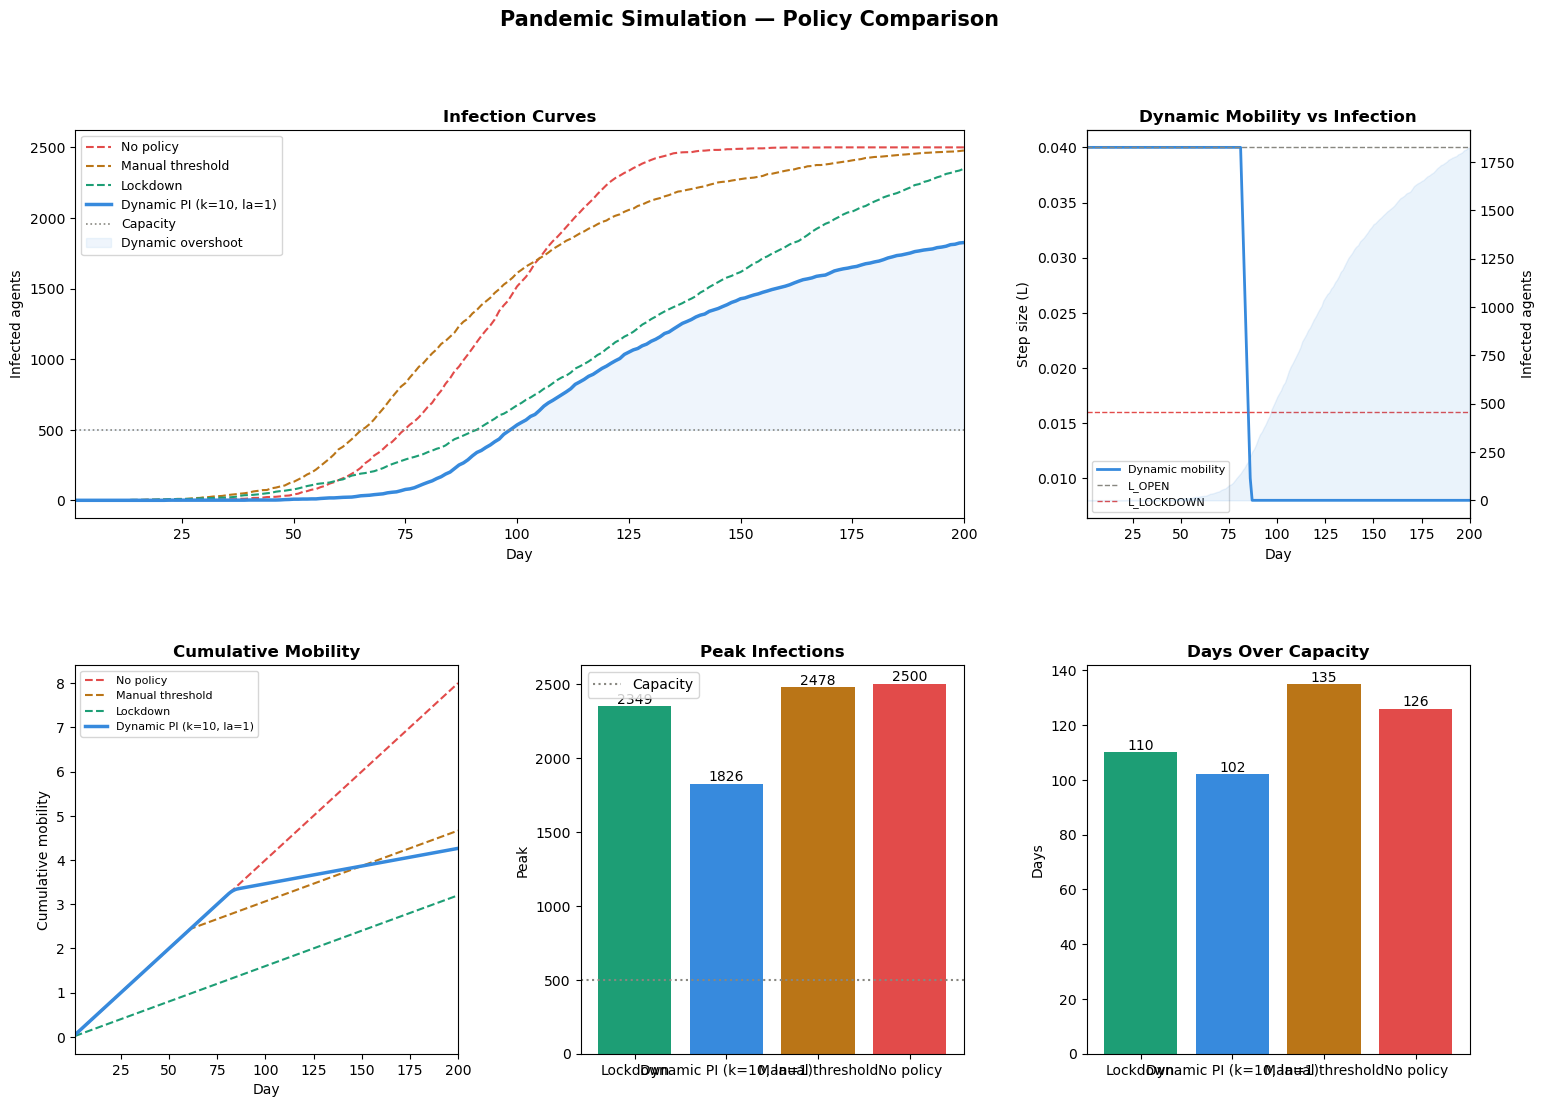

In [2]:
# --- 11. PLOTS ---
COLORS = {
    "lockdown": "#1D9E75",
    "none":     "#E24B4A",
    "manual":   "#BA7517",
    "dynamic":  "#378ADD",
}

LABELS = {
    "lockdown": "Lockdown",
    "none":     "No policy",
    "manual":   "Manual threshold",
    "dynamic":  f"Dynamic PI (k={best_k}, la={best_la})",
}

fig = plt.figure(figsize=(18, 12))
fig.suptitle("Pandemic Simulation — Policy Comparison", fontsize=15, fontweight="bold", y=0.98)

gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.38, wspace=0.32)

ax1 = fig.add_subplot(gs[0, :2])  # Infection curves
ax2 = fig.add_subplot(gs[0, 2])   # Mobility vs infection
ax3 = fig.add_subplot(gs[1, 0])   # Cumulative mobility
ax4 = fig.add_subplot(gs[1, 1])   # Peak infections
ax5 = fig.add_subplot(gs[1, 2])   # Days over capacity

days = np.arange(1, DAYS + 1)

# --- Infection curves ---
for key in ["none", "manual", "lockdown", "dynamic"]:
    lw = 2.5 if key == "dynamic" else 1.5
    ls = "-" if key == "dynamic" else "--"

    ax1.plot(
        days,
        data[key]["history"],
        color=COLORS[key],
        lw=lw,
        ls=ls,
        label=LABELS[key],
    )

ax1.axhline(CAPACITY_LIMIT, color="#888780", lw=1.2, ls=":", label="Capacity")

ax1.fill_between(
    days,
    CAPACITY_LIMIT,
    np.maximum(data["dynamic"]["history"], CAPACITY_LIMIT),
    color=COLORS["dynamic"],
    alpha=0.08,
    label="Dynamic overshoot",
)

ax1.set_title("Infection Curves", fontweight="bold")
ax1.set_xlabel("Day")
ax1.set_ylabel("Infected agents")
ax1.legend(fontsize=9)
ax1.set_xlim(1, DAYS)


# --- Mobility vs Infection ---
ax2.plot(
    days,
    data["dynamic"]["mobility"],
    color=COLORS["dynamic"],
    lw=2,
    label="Dynamic mobility",
)

ax2.axhline(L_OPEN, color="#888780", lw=1, ls="--", label="L_OPEN")
ax2.axhline(L_LOCKDOWN, color="#E24B4A", lw=1, ls="--", label="L_LOCKDOWN")

ax2_twin = ax2.twinx()

ax2_twin.fill_between(
    days,
    data["dynamic"]["history"],
    color=COLORS["dynamic"],
    alpha=0.1,
)

ax2.set_title("Dynamic Mobility vs Infection", fontweight="bold")
ax2.set_xlabel("Day")
ax2.set_ylabel("Step size (L)")
ax2_twin.set_ylabel("Infected agents")

ax2.legend(fontsize=8)
ax2.set_xlim(1, DAYS)


# --- Cumulative mobility ---
for key in ["none", "manual", "lockdown", "dynamic"]:
    lw = 2.5 if key == "dynamic" else 1.5
    ls = "-" if key == "dynamic" else "--"

    ax3.plot(
        days,
        np.cumsum(data[key]["mobility"]),
        color=COLORS[key],
        lw=lw,
        ls=ls,
        label=LABELS[key],
    )

ax3.set_title("Cumulative Mobility", fontweight="bold")
ax3.set_xlabel("Day")
ax3.set_ylabel("Cumulative mobility")
ax3.legend(fontsize=8)
ax3.set_xlim(1, DAYS)


# --- Peak infections ---
keys_ord = ["lockdown", "dynamic", "manual", "none"]
peaks = [data[k]["metrics"]["Peak"] for k in keys_ord]

bars = ax4.bar(
    [LABELS[k] for k in keys_ord],
    peaks,
    color=[COLORS[k] for k in keys_ord],
)

ax4.axhline(CAPACITY_LIMIT, color="#888780", ls=":", label="Capacity")

for bar, val in zip(bars, peaks):
    ax4.text(
        bar.get_x() + bar.get_width() / 2,
        val + 20,
        f"{val}",
        ha="center",
    )

ax4.set_title("Peak Infections", fontweight="bold")
ax4.set_ylabel("Peak")
ax4.legend()


# --- Days over capacity ---
days_over = [data[k]["metrics"]["Days Over Cap"] for k in keys_ord]

bars2 = ax5.bar(
    [LABELS[k] for k in keys_ord],
    days_over,
    color=[COLORS[k] for k in keys_ord],
)

for bar, val in zip(bars2, days_over):
    ax5.text(
        bar.get_x() + bar.get_width() / 2,
        val + 1,
        str(val),
        ha="center",
    )

ax5.set_title("Days Over Capacity", fontweight="bold")
ax5.set_ylabel("Days")


plt.show()

## DQN + PI v3

Running baseline scenarios...
  lockdown... done
  none... done
  manual... done
  dynamic_pi (5-run ensemble)... done
  pid (5-run ensemble)... done

Training DQN+PI v3 (180 episodes, ~150-200 target)...
  Warm-filling replay buffer (30 PI + 30 PID episodes)... 11460 transitions loaded
  Ep  25/180 [curriculum]  avg_r=-1174.4  eval_peak=2121±515  eval_dov=109d  eval_mob=4.29  ε=0.509  best=2121
  Ep  50/180 [curriculum]  avg_r=-1097.1  eval_peak=2396±146  eval_dov=127d  eval_mob=4.06  ε=0.343  best=2121
  Ep  75/180 [freezing]  avg_r=-1046.3  eval_peak=2245±310  eval_dov=127d  eval_mob=3.98  ε=0.233  best=2121
  Ep 100/180 [exploit]  avg_r=-1108.8  eval_peak=2339±119  eval_dov=128d  eval_mob=3.59  ε=0.020  best=2121
  Ep 125/180 [exploit]  avg_r=-1046.6  eval_peak=2440±52   eval_dov=124d  eval_mob=4.21  ε=0.020  best=2121
  Ep 150/180 [exploit]  avg_r=-1128.2  eval_peak=2131±221  eval_dov=121d  eval_mob=3.66  ε=0.020  best=2121
  Ep 175/180 [exploit]  avg_r=-1116.9  eval_peak=1830±541

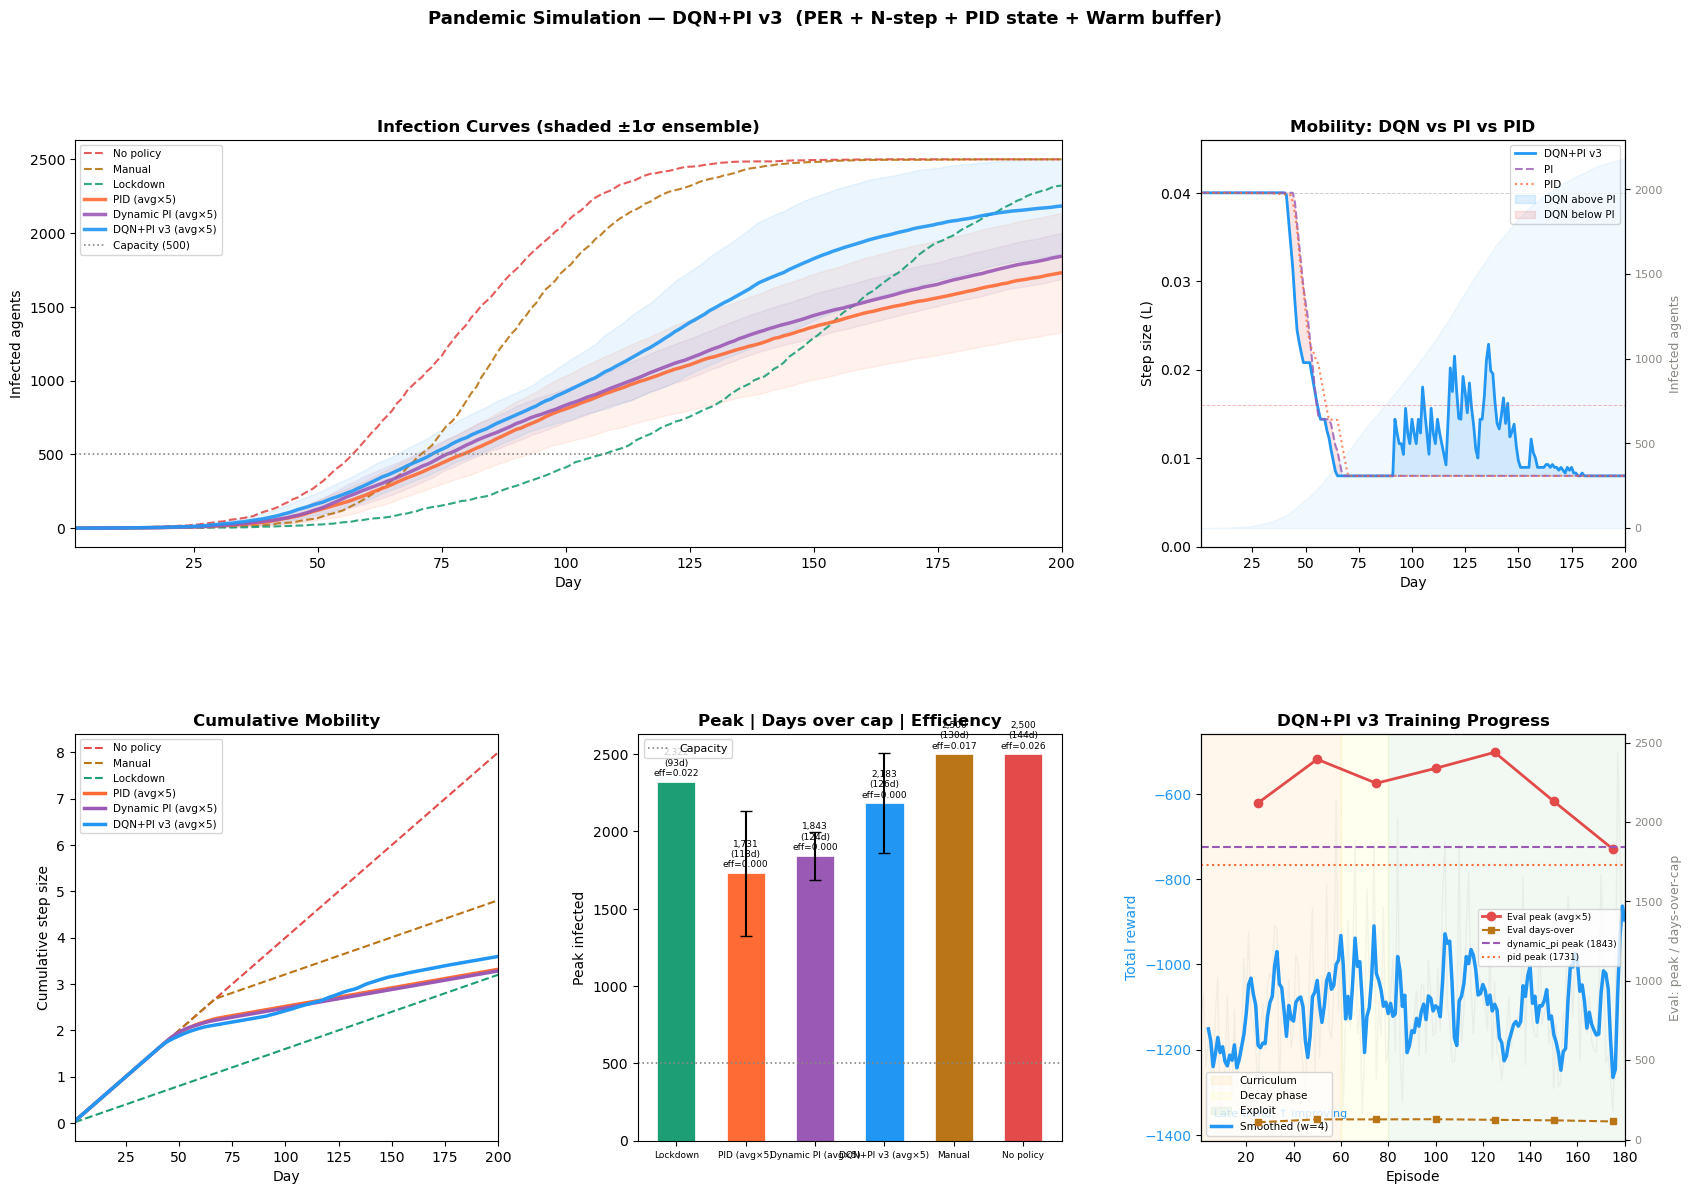


Plot saved → pandemic_dqn_pi_v3_results.png


In [3]:
"""
Pandemic Simulation — DQN+PI v3
================================
New in this version:

1. PID CONTROLLER (new baseline)
   Full PID = PI + Derivative term.
   The derivative term penalises the RATE OF CHANGE of the error signal,
   dampening oscillations and responding faster to acceleration.
   Added as both a standalone policy AND as a state feature for the DQN.

2. PID OUTPUT AS DQN STATE FEATURE
   The DQN now sees what BOTH PI and PID are suggesting.
   If PI says "restrict a little" but PID says "restrict hard" (because
   derivative is spiking), the DQN can learn to follow the more aggressive
   signal. This gives the network a direct handle on the second derivative.

3. EPSILON SCHEDULE FIXED: hard freeze at episode 80
   Previous version had epsilon=0.174 at ep150 — stochastic actions during
   greedy eval caused the apparent regression. Now epsilon drops to 0.02
   by episode 80 and stays there, so eval is nearly deterministic.

4. WARM REPLAY BUFFER: pre-fill with PI+PID expert trajectories
   Before training starts, run 30 PI and 30 PID episodes and fill the
   replay buffer. This means the network trains on good trajectories from
   episode 1, not random garbage. Critical when episodes are limited.

5. REWARD TUNED TO BEAT PI PEAK SPECIFICALLY
   Added a "PI-relative" reward component: explicit bonus for days where
   DQN infections are BELOW what PI would have produced. This directly
   trains the network to outperform PI on the metric that matters.
"""

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.spatial.distance import cdist
from collections import deque
import random, copy

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

# =============================================================================
# 1. GLOBAL PARAMETERS
# =============================================================================
NUM_AGENTS     = 2500
GRID_SIZE      = 1.0
DAYS           = 200
CAPACITY_LIMIT = 500

R_AVG         = 1.0 / np.sqrt(NUM_AGENTS)
INF_RADIUS    = R_AVG / 5.0
INF_RADIUS_SQ = INF_RADIUS ** 2

L_LOCKDOWN = 0.016
L_OPEN     = 2.0 * R_AVG
L_RANGE    = L_OPEN - L_LOCKDOWN

PI_K          = 6
PI_LOOK_AHEAD = 3

# PID derivative gain
PID_KD = 0.8

# Training — tuned for 150-200 episodes
EPISODES        = 180
BATCH_SIZE      = 256
REPLAY_CAPACITY = 60_000
LR              = 2e-4
GAMMA           = 0.97
N_STEP          = 10
TARGET_UPDATE   = 6
EPS_START       = 0.75
EPS_FREEZE_EP   = 80          # hard freeze epsilon after this episode
EPS_FROZEN      = 0.02        # frozen value — nearly greedy
EPS_DECAY       = 60
WARM_EPISODES   = 30          # PI expert episodes to pre-fill buffer
EVAL_RUNS       = 5
PER_ALPHA       = 0.6
PER_BETA_START  = 0.4
PER_BETA_END    = 1.0

BLEND_WEIGHTS = [-0.3, -0.15, -0.05, 0.0, 0.05, 0.15, 0.3, 0.5, 0.8, 1.0]
NUM_ACTIONS   = len(BLEND_WEIGHTS)
STATE_DIM     = 10   # +2 for PID suggestion and PID-PI delta


# =============================================================================
# 2. SIMULATION PRIMITIVES
# =============================================================================

def infect_grid(positions, status, inf_radius_sq, grid_size=20):
    G = grid_size
    cells     = [[] for _ in range(G * G)]
    inf_cells = [[] for _ in range(G * G)]
    for i in range(len(positions)):
        gx  = min(G-1, int(positions[i, 0] * G))
        gy  = min(G-1, int(positions[i, 1] * G))
        idx = gy * G + gx
        (inf_cells if status[i] == 1 else cells)[idx].append(i)
    new_infected = []
    for cy in range(G):
        for cx in range(G):
            sus = cells[cy * G + cx]
            if not sus: continue
            for dy in range(-1, 2):
                for dx in range(-1, 2):
                    ny, nx = cy+dy, cx+dx
                    if not (0 <= ny < G and 0 <= nx < G): continue
                    infs = inf_cells[ny * G + nx]
                    for si in sus:
                        if status[si] == 1: continue
                        for ii in infs:
                            d2 = ((positions[si,0]-positions[ii,0])**2
                                + (positions[si,1]-positions[ii,1])**2)
                            if d2 <= inf_radius_sq:
                                new_infected.append(si); break
    for si in new_infected: status[si] = 1


def move_agents(positions, l):
    a = np.random.uniform(0, 2*np.pi, len(positions))
    positions[:, 0] += l * np.cos(a)
    positions[:, 1] += l * np.sin(a)
    positions[:] = np.abs(positions)
    positions[:] = np.where(positions > GRID_SIZE, 2*GRID_SIZE - positions, positions)


def seed_population(fixed_seed=None):
    rng = np.random.RandomState(fixed_seed) if fixed_seed is not None else np.random
    positions = rng.rand(NUM_AGENTS, 2)
    status    = np.zeros(NUM_AGENTS, dtype=np.uint8)
    status[np.argmin(cdist(positions, [[0.5, 0.5]]))] = 1
    return positions, status


# =============================================================================
# 3. PI CONTROLLER
# =============================================================================

def pi_step(current_inf, recent_inf, prev_l, integral,
            k=PI_K, look_ahead=PI_LOOK_AHEAD):
    cap_ratio = current_inf / CAPACITY_LIMIT
    trend = 0.0
    if len(recent_inf) >= 2:
        trend = (recent_inf[-1] - recent_inf[0]) / (len(recent_inf)-1) / CAPACITY_LIMIT
    if cap_ratio > 1.0:
        integral = min(integral + (cap_ratio - 1.0) * 0.05, 1.0)
    else:
        integral = max(0.0, integral - 0.01)
    predictive = cap_ratio + look_ahead * max(0.0, trend)
    if predictive < 0.3:
        target_l = L_OPEN
    elif predictive < 0.8:
        t = (predictive - 0.3) / 0.5
        target_l = L_OPEN * np.exp(-k * t)
    else:
        target_l = L_OPEN * np.exp(-k) * np.exp(-k * integral)
    hyst = 0.6 if prev_l < L_OPEN * 0.5 else 1.0
    if cap_ratio > hyst * 0.8:
        target_l = min(target_l, prev_l)
    max_delta = 0.15 * L_OPEN
    l = float(np.clip(target_l, prev_l - max_delta, prev_l + max_delta))
    l = float(np.clip(l, L_LOCKDOWN * 0.5, L_OPEN))
    return l, integral


# =============================================================================
# 4. PID CONTROLLER  (new — adds derivative term to PI)
# =============================================================================

def pid_step(current_inf, recent_inf, prev_l, integral, prev_error,
             k=PI_K, look_ahead=PI_LOOK_AHEAD, kd=PID_KD):
    """
    Full PID controller.
    The derivative term acts on d(error)/dt where error = cap_ratio - setpoint.
    This dampens overshoot: when infections are rising fast, the derivative
    fires BEFORE the proportional term catches up, giving faster restriction.

    Setpoint = 0.7 × CAPACITY_LIMIT (target operating point below cap).
    error     = (current_inf / CAP) - 0.7
    d_error   = error - prev_error  (per-step derivative)

    The PID output is the PI output MINUS a correction proportional to d_error:
    If error is growing fast (d_error > 0), PID restricts MORE than PI.
    If error is shrinking (d_error < 0, infections falling), PID opens FASTER.
    """
    # Get PI base
    pi_l, integral = pi_step(current_inf, recent_inf, prev_l, integral, k, look_ahead)

    setpoint = 0.7
    error    = (current_inf / CAPACITY_LIMIT) - setpoint
    d_error  = error - prev_error

    # Derivative correction: negative d_error means things improving → open more
    deriv_correction = kd * d_error * L_RANGE

    pid_l = float(np.clip(pi_l - deriv_correction, L_LOCKDOWN * 0.5, L_OPEN))

    return pid_l, integral, error


def run_pid():
    """Standalone PID policy run."""
    positions, status = seed_population()
    history, mobility = [], []
    prev_l   = L_OPEN; integral = 0.0; recent = []; prev_err = 0.0
    for _ in range(DAYS):
        current_inf = int(np.sum(status))
        recent.append(current_inf)
        if len(recent) > PI_LOOK_AHEAD + 1: recent.pop(0)
        l, integral, prev_err = pid_step(current_inf, recent, prev_l, integral, prev_err)
        prev_l = l
        mobility.append(l); move_agents(positions, l)
        infect_grid(positions, status, INF_RADIUS_SQ)
        history.append(current_inf)
    return np.array(history), np.array(mobility)


# =============================================================================
# 5. BASELINES
# =============================================================================

def run_baseline(policy_type="lockdown"):
    positions, status = seed_population()
    history, mobility = [], []
    for _ in range(DAYS):
        current_inf = int(np.sum(status))
        if policy_type == "lockdown":   l = L_LOCKDOWN
        elif policy_type == "none":     l = L_OPEN
        elif policy_type == "manual":   l = L_LOCKDOWN if current_inf > 0.8*CAPACITY_LIMIT else L_OPEN
        else: raise ValueError(policy_type)
        mobility.append(l); move_agents(positions, l)
        infect_grid(positions, status, INF_RADIUS_SQ); history.append(current_inf)
    return np.array(history), np.array(mobility)


def run_dynamic_pi():
    positions, status = seed_population()
    history, mobility = [], []
    prev_l = L_OPEN; integral = 0.0; recent = []
    for _ in range(DAYS):
        current_inf = int(np.sum(status))
        recent.append(current_inf)
        if len(recent) > PI_LOOK_AHEAD + 1: recent.pop(0)
        l, integral = pi_step(current_inf, recent, prev_l, integral)
        prev_l = l
        mobility.append(l); move_agents(positions, l)
        infect_grid(positions, status, INF_RADIUS_SQ); history.append(current_inf)
    return np.array(history), np.array(mobility)


# =============================================================================
# 6. STATE VECTOR  (10-dim, includes PID suggestion)
# =============================================================================

def build_state_vector(current_inf, inf_history, pi_l, pid_l, prev_l, day):
    """
    10-dimensional state:
      f0: cap_ratio (sqrt-scaled)
      f1: 3-day acceleration
      f2: 7-day trend
      f3: pi_ratio         (what PI suggests)
      f4: pid_ratio        (what PID suggests)  ← NEW
      f5: pid_minus_pi     (PID - PI delta, captures derivative urgency)  ← NEW
      f6: current mob ratio
      f7: PI urgency (1=locked, 0=open)
      f8: day / DAYS
      f9: susceptible fraction
    """
    h = list(inf_history)
    cap_ratio = current_inf / CAPACITY_LIMIT

    f0 = float(np.sqrt(np.clip(cap_ratio / 2.0, 0.0, 1.0)))

    if len(h) >= 3:
        accel = (h[-1] - 2*h[-2] + h[-3]) / CAPACITY_LIMIT
    else:
        accel = 0.0
    f1 = float(np.clip(accel / 0.10, -1.0, 1.0))

    if len(h) >= 7:
        t7 = (h[-1] - h[-7]) / (6.0 * CAPACITY_LIMIT)
    elif len(h) >= 2:
        t7 = (h[-1] - h[0]) / (max(len(h)-1, 1) * CAPACITY_LIMIT)
    else:
        t7 = 0.0
    f2 = float(np.clip(t7 / 0.10, -1.0, 1.0))

    f3 = float((pi_l  - L_LOCKDOWN) / L_RANGE)
    f4 = float((pid_l - L_LOCKDOWN) / L_RANGE)
    f5 = float(np.clip((pid_l - pi_l) / L_RANGE, -1.0, 1.0))  # PID-PI delta
    f6 = float((prev_l - L_LOCKDOWN) / L_RANGE)
    f7 = float(1.0 - (pi_l - L_LOCKDOWN) / L_RANGE)
    f8 = float(day / DAYS)
    f9 = float(1.0 - current_inf / NUM_AGENTS)

    return np.array([f0, f1, f2, f3, f4, f5, f6, f7, f8, f9], dtype=np.float32)


# =============================================================================
# 7. PRIORITISED REPLAY BUFFER
# =============================================================================

class PrioritisedReplayBuffer:
    def __init__(self, capacity, alpha=PER_ALPHA):
        self.capacity  = capacity
        self.alpha     = alpha
        self.buffer    = []
        self.pos       = 0
        self.priorities = np.zeros(capacity, dtype=np.float32)

    def push(self, *transition):
        max_prio = self.priorities.max() if self.buffer else 1.0
        if len(self.buffer) < self.capacity:
            self.buffer.append(transition)
        else:
            self.buffer[self.pos] = transition
        self.priorities[self.pos] = max_prio
        self.pos = (self.pos + 1) % self.capacity

    def sample(self, batch_size, beta):
        n     = len(self.buffer)
        prios = self.priorities[:n]
        probs = prios ** self.alpha
        probs /= probs.sum()
        indices = np.random.choice(n, batch_size, p=probs, replace=False)
        samples = [self.buffer[i] for i in indices]
        weights = (n * probs[indices]) ** (-beta)
        weights /= weights.max()
        s, a, r, ns, d = zip(*samples)
        return (np.array(s), np.array(a), np.array(r, dtype=np.float32),
                np.array(ns), np.array(d, dtype=np.float32),
                indices, np.array(weights, dtype=np.float32))

    def update_priorities(self, indices, td_errors):
        for idx, err in zip(indices, td_errors):
            self.priorities[idx] = abs(err) + 1e-6

    def __len__(self): return len(self.buffer)


# =============================================================================
# 8. N-STEP BUFFER
# =============================================================================

class NStepBuffer:
    def __init__(self, n, gamma):
        self.n = n; self.gamma = gamma; self.buf = deque()

    def push(self, *t): self.buf.append(t)
    def ready(self): return len(self.buf) >= self.n

    def get(self):
        s0, a0, _, _, _ = self.buf[0]
        ret = sum((self.gamma**i) * r for i, (_, _, r, _, d) in enumerate(list(self.buf)[:self.n]))
        _, _, _, sn, dn = self.buf[self.n - 1]
        self.buf.popleft()
        return s0, a0, ret, sn, dn

    def clear(self): self.buf.clear()


# =============================================================================
# 9. REWARD  (PI-relative component added)
# =============================================================================

def compute_reward(next_inf, l, current_inf, pi_l, pid_l, inf_history, pi_shadow_inf):
    """
    PI-relative reward: explicit bonus for days where DQN infection is
    below what PI would have produced (pi_shadow_inf).
    This is the direct training signal for "beat PI on peak infections."

    pi_shadow_inf: infection count from a shadow PI run (same random seed),
    used as a counterfactual baseline. When DQN < PI shadow, it gets a bonus.
    """
    cap_ratio = next_inf / CAPACITY_LIMIT
    mob_ratio = (l - L_LOCKDOWN) / L_RANGE
    mob_vs_pi = (l - pi_l) / L_RANGE

    if len(inf_history) >= 3:
        accel = (inf_history[-1] - 2*inf_history[-2] + inf_history[-3]) / CAPACITY_LIMIT
    else:
        accel = 0.0

    # 1. Gated mobility reward
    if cap_ratio < 0.5:    gate = 1.0
    elif cap_ratio < 1.0:  gate = 1.0 - (cap_ratio - 0.5) / 0.5
    else:                  gate = 0.0
    mob_reward = 2.0 * mob_ratio * gate

    # 2. Overload penalty
    if cap_ratio > 1.0:
        overload_pen = -4.0 - 10.0 * (cap_ratio - 1.0) ** 2
    elif cap_ratio > 0.85:
        overload_pen = -1.5 * ((cap_ratio - 0.85) / 0.15) ** 2
    else:
        overload_pen = 0.0

    # 3. Acceleration penalty
    accel_pen = -2.5 * max(0.0, accel)

    # 4. Opening above PI (safe zones only)
    if cap_ratio < 0.45 and accel < 0.015 and mob_vs_pi > 0:
        open_bonus = 0.5 * mob_vs_pi
    else:
        open_bonus = 0.0

    # 5. Pre-emptive tightening vs PID
    # Reward for being tighter than PID when PID is already restricting
    pid_vs_pi = (pid_l - pi_l) / L_RANGE   # negative = PID more restrictive
    if pid_vs_pi < -0.05 and l <= pid_l:
        # PID is restricting harder than PI AND we followed the PID signal
        tighten_bonus = 0.35 * abs(pid_vs_pi)
    elif accel > 0.025 and mob_vs_pi < 0:
        tighten_bonus = 0.4 * abs(mob_vs_pi)
    else:
        tighten_bonus = 0.0

    # 6. PI-relative bonus: reward for being below PI shadow infections
    if pi_shadow_inf is not None:
        pi_relative = (pi_shadow_inf - next_inf) / CAPACITY_LIMIT
        pi_bonus = 0.8 * np.clip(pi_relative, -0.5, 1.0)
    else:
        pi_bonus = 0.0

    reward = mob_reward + overload_pen + accel_pen + open_bonus + tighten_bonus + pi_bonus
    return float(np.clip(reward, -10.0, 3.0))


# =============================================================================
# 10. DQN NETWORK
# =============================================================================

class DQN(nn.Module):
    def __init__(self, state_dim=STATE_DIM, num_actions=NUM_ACTIONS, hidden=96):
        super().__init__()
        self.shared = nn.Sequential(
            nn.Linear(state_dim, hidden), nn.LayerNorm(hidden), nn.ReLU(),
            nn.Linear(hidden, hidden),   nn.LayerNorm(hidden), nn.ReLU(),
        )
        self.value_stream = nn.Sequential(nn.Linear(hidden, 48), nn.ReLU(), nn.Linear(48, 1))
        self.adv_stream   = nn.Sequential(nn.Linear(hidden, 48), nn.ReLU(), nn.Linear(48, num_actions))

    def forward(self, x):
        h = self.shared(x)
        v = self.value_stream(h)
        a = self.adv_stream(h)
        return v + a - a.mean(dim=-1, keepdim=True)


# =============================================================================
# 11. WARM REPLAY: pre-fill buffer with PI and PID expert trajectories
# =============================================================================

def warm_fill_replay(replay, n_pi=15, n_pid=15, fixed_seed=None):
    """
    Run PI and PID episodes and fill the replay buffer before training.
    These expert trajectories guarantee the buffer has good examples of
    infection-controlling behaviour from the very first training batch.
    """
    print(f"  Warm-filling replay buffer ({n_pi} PI + {n_pid} PID episodes)...",
          end="", flush=True)

    nstep_buf = NStepBuffer(N_STEP, GAMMA)

    for mode in (["pi"] * n_pi + ["pid"] * n_pid):
        seed = None  # vary seeds for diversity
        positions, status = seed_population(seed)

        # Run a shadow PI in parallel to get pi_shadow_inf
        pi_pos, pi_status = seed_population(seed)
        pi_prev_l = L_OPEN; pi_int = 0.0; pi_recent = []

        prev_l   = L_OPEN; integral = 0.0; recent = []; prev_err = 0.0
        inf_history = [1] * 8
        nstep_buf.clear()

        for day in range(DAYS):
            current_inf = int(np.sum(status))
            inf_history.append(current_inf)
            if len(inf_history) > 8: inf_history.pop(0)
            recent.append(current_inf)
            if len(recent) > PI_LOOK_AHEAD + 1: recent.pop(0)

            # PI shadow step
            pi_recent.append(int(np.sum(pi_status)))
            if len(pi_recent) > PI_LOOK_AHEAD + 1: pi_recent.pop(0)
            pi_l_shadow, pi_int = pi_step(int(np.sum(pi_status)), pi_recent, pi_prev_l, pi_int)
            move_agents(pi_pos, pi_l_shadow)
            infect_grid(pi_pos, pi_status, INF_RADIUS_SQ)
            pi_shadow_inf = int(np.sum(pi_status))
            pi_prev_l = pi_l_shadow

            pi_l, _ = pi_step(current_inf, recent, prev_l, 0.0)
            pid_l, integral, prev_err = pid_step(current_inf, recent, prev_l, integral, prev_err)

            state = build_state_vector(current_inf, inf_history, pi_l, pid_l, prev_l, day)

            # Expert action: for PI episodes use w=0, for PID use the PID blend
            if mode == "pi":
                l = float(np.clip(pi_l, L_LOCKDOWN * 0.5, L_OPEN))
                a_idx = 3  # w=0.0
            else:
                l = float(np.clip(pid_l, L_LOCKDOWN * 0.5, L_OPEN))
                w_target = (pid_l - pi_l) / (L_OPEN - pi_l + 1e-9)
                a_idx = int(np.argmin([abs(w - w_target) for w in BLEND_WEIGHTS]))

            move_agents(positions, l)
            infect_grid(positions, status, INF_RADIUS_SQ)
            next_inf = int(np.sum(status))

            inf_h_next = (inf_history + [next_inf])[-8:]
            pi_l_next, _ = pi_step(next_inf, (recent + [next_inf])[-PI_LOOK_AHEAD-1:], l, 0.0)
            pid_l_next, _, _ = pid_step(next_inf, (recent+[next_inf])[-PI_LOOK_AHEAD-1:], l, 0.0, prev_err)
            next_state = build_state_vector(next_inf, inf_h_next, pi_l_next, pid_l_next, l, day+1)

            reward = compute_reward(next_inf, l, current_inf, pi_l, pid_l, inf_history, pi_shadow_inf)
            done   = float(day == DAYS - 1)

            nstep_buf.push(state, a_idx, reward, next_state, done)
            if nstep_buf.ready():
                replay.push(*nstep_buf.get())

            prev_l = l

    print(f" {len(replay)} transitions loaded")


# =============================================================================
# 12. TRAINING
# =============================================================================

def train_dqn(episodes=EPISODES, verbose=True):
    device     = torch.device("cpu")
    policy_net = DQN().to(device)
    target_net = DQN().to(device)
    target_net.load_state_dict(policy_net.state_dict())
    target_net.eval()

    optimizer = optim.Adam(policy_net.parameters(), lr=LR, weight_decay=1e-5)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=episodes, eta_min=LR/10)
    replay    = PrioritisedReplayBuffer(REPLAY_CAPACITY)
    nstep     = NStepBuffer(N_STEP, GAMMA)

    # Pre-fill replay with expert PI/PID trajectories
    warm_fill_replay(replay, n_pi=WARM_EPISODES, n_pid=WARM_EPISODES)

    episode_rewards = []
    eval_peaks, eval_mobs, eval_dov, eval_episodes = [], [], [], []
    best_eval_peak  = float("inf")
    best_net_state  = None

    for ep in range(episodes):
        # Curriculum: fixed seeds for first 60 episodes
        fixed_seed = (ep * 7 + 13) % 40 if ep < 60 else None
        positions, status = seed_population(fixed_seed)

        # Parallel PI shadow run (same seed) for pi_relative reward
        pi_pos, pi_status = seed_population(fixed_seed)
        pi_prev_l_sh = L_OPEN; pi_int_sh = 0.0; pi_recent_sh = []

        prev_l   = L_OPEN; integral = 0.0; recent = []; prev_err = 0.0
        ep_reward = 0.0
        inf_history = [1] * 8
        nstep.clear()

        # Epsilon: fast decay to EPS_FROZEN, then stay frozen
        if ep < EPS_FREEZE_EP:
            epsilon = EPS_FROZEN + (EPS_START - EPS_FROZEN) * np.exp(-ep / EPS_DECAY)
        else:
            epsilon = EPS_FROZEN

        beta = PER_BETA_START + (PER_BETA_END - PER_BETA_START) * min(1.0, ep / episodes)

        for day in range(DAYS):
            current_inf = int(np.sum(status))
            inf_history.append(current_inf)
            if len(inf_history) > 8: inf_history.pop(0)
            recent.append(current_inf)
            if len(recent) > PI_LOOK_AHEAD + 1: recent.pop(0)

            # PI shadow step
            pi_recent_sh.append(int(np.sum(pi_status)))
            if len(pi_recent_sh) > PI_LOOK_AHEAD+1: pi_recent_sh.pop(0)
            pi_l_shadow, pi_int_sh = pi_step(
                int(np.sum(pi_status)), pi_recent_sh, pi_prev_l_sh, pi_int_sh)
            move_agents(pi_pos, pi_l_shadow)
            infect_grid(pi_pos, pi_status, INF_RADIUS_SQ)
            pi_shadow_inf = int(np.sum(pi_status))
            pi_prev_l_sh = pi_l_shadow

            pi_l, _           = pi_step(current_inf, recent, prev_l, 0.0)
            pid_l, integral, prev_err = pid_step(current_inf, recent, prev_l, integral, prev_err)
            state = build_state_vector(current_inf, inf_history, pi_l, pid_l, prev_l, day)

            # Action selection
            cap_ratio = current_inf / CAPACITY_LIMIT
            accel_now = (inf_history[-1]-2*inf_history[-2]+inf_history[-3]) / CAPACITY_LIMIT \
                        if len(inf_history) >= 3 else 0.0

            if random.random() < epsilon:
                if cap_ratio > 0.8 or accel_now > 0.04:
                    probs = np.array([5,4,2,1.5,0.5,0.2,0.1,0.05,0.02,0.02], dtype=float)
                elif cap_ratio > 0.5:
                    probs = np.array([2,2,1.5,1.5,1,0.8,0.5,0.2,0.1,0.1], dtype=float)
                elif cap_ratio < 0.2 and accel_now < 0:
                    probs = np.array([0.05,0.1,0.2,0.4,1,2,3,4,4.5,5], dtype=float)
                else:
                    probs = np.ones(NUM_ACTIONS, dtype=float)
                probs /= probs.sum()
                a_idx = int(np.random.choice(NUM_ACTIONS, p=probs))
            else:
                with torch.no_grad():
                    s_t   = torch.FloatTensor(state).unsqueeze(0).to(device)
                    a_idx = int(policy_net(s_t).argmax().item())

            w   = BLEND_WEIGHTS[a_idx]
            l   = float(np.clip(pi_l + w*(L_OPEN - pi_l), L_LOCKDOWN*0.5, L_OPEN))

            move_agents(positions, l)
            infect_grid(positions, status, INF_RADIUS_SQ)

            next_inf = int(np.sum(status))
            ih_next  = (inf_history + [next_inf])[-8:]
            nr       = (recent + [next_inf])[-PI_LOOK_AHEAD-1:]
            pi_ln, _ = pi_step(next_inf, nr, l, 0.0)
            pid_ln, _, _ = pid_step(next_inf, nr, l, 0.0, prev_err)
            next_state = build_state_vector(next_inf, ih_next, pi_ln, pid_ln, l, day+1)

            reward    = compute_reward(next_inf, l, current_inf, pi_l, pid_l, inf_history, pi_shadow_inf)
            done      = float(day == DAYS - 1)
            ep_reward += reward

            nstep.push(state, a_idx, reward, next_state, done)
            if nstep.ready():
                replay.push(*nstep.get())

            # Training step
            if len(replay) >= BATCH_SIZE:
                sb, ab, rb, nsb, db, idxs, wts = replay.sample(BATCH_SIZE, beta)
                sb  = torch.FloatTensor(sb).to(device)
                ab  = torch.LongTensor(ab).to(device)
                rb  = torch.FloatTensor(rb).to(device)
                nsb = torch.FloatTensor(nsb).to(device)
                db  = torch.FloatTensor(db).to(device)
                wts = torch.FloatTensor(wts).to(device)

                with torch.no_grad():
                    na  = policy_net(nsb).argmax(dim=1)
                    nq  = target_net(nsb).gather(1, na.unsqueeze(1)).squeeze(1)
                    tq  = rb + (GAMMA**N_STEP) * nq * (1.0 - db)

                cq  = policy_net(sb).gather(1, ab.unsqueeze(1)).squeeze(1)
                td  = (cq - tq).detach().cpu().numpy()
                replay.update_priorities(idxs, td)

                loss = (wts * F.smooth_l1_loss(cq, tq, reduction='none')).mean()
                optimizer.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(policy_net.parameters(), 5.0)
                optimizer.step()

            prev_l = l

        if (ep + 1) % TARGET_UPDATE == 0:
            target_net.load_state_dict(policy_net.state_dict())
        scheduler.step()
        episode_rewards.append(ep_reward)

        if verbose and (ep + 1) % 25 == 0:
            peaks_e, mobs_e, dovs_e = [], [], []
            for _ in range(EVAL_RUNS):
                he, me = run_dqn_policy(policy_net, device, silent=True)
                peaks_e.append(int(np.max(he)))
                mobs_e.append(float(np.sum(me)))
                dovs_e.append(int(np.sum(he > CAPACITY_LIMIT)))

            ep_mean = int(np.mean(peaks_e))
            eval_peaks.append(ep_mean)
            eval_mobs.append(float(np.mean(mobs_e)))
            eval_dov.append(int(np.mean(dovs_e)))
            eval_episodes.append(ep + 1)

            # Save best network
            if ep_mean < best_eval_peak:
                best_eval_peak = ep_mean
                best_net_state = copy.deepcopy(policy_net.state_dict())

            phase = "curriculum" if ep < 60 else ("freezing" if ep < EPS_FREEZE_EP else "exploit")
            avg   = np.mean(episode_rewards[-25:])
            print(f"  Ep {ep+1:>3}/{episodes} [{phase}]  "
                  f"avg_r={avg:+.1f}  "
                  f"eval_peak={ep_mean:>4}±{int(np.std(peaks_e)):<3}  "
                  f"eval_dov={eval_dov[-1]:>3}d  "
                  f"eval_mob={eval_mobs[-1]:.2f}  "
                  f"ε={epsilon:.3f}  best={best_eval_peak}")

    # Restore best network (not last)
    if best_net_state is not None:
        policy_net.load_state_dict(best_net_state)
        print(f"\n→ Restored best network (eval_peak={best_eval_peak})")

    return policy_net, device, episode_rewards, eval_peaks, eval_mobs, eval_dov, eval_episodes


# =============================================================================
# 13. GREEDY EXECUTION
# =============================================================================

def run_dqn_policy(policy_net, device, silent=False):
    policy_net.eval()
    positions, status = seed_population()
    prev_l   = L_OPEN; integral = 0.0; recent = []; prev_err = 0.0
    history, mobility = [], []
    inf_history = [1] * 8

    with torch.no_grad():
        for day in range(DAYS):
            current_inf = int(np.sum(status))
            inf_history.append(current_inf)
            if len(inf_history) > 8: inf_history.pop(0)
            recent.append(current_inf)
            if len(recent) > PI_LOOK_AHEAD + 1: recent.pop(0)

            pi_l, _           = pi_step(current_inf, recent, prev_l, 0.0)
            pid_l, integral, prev_err = pid_step(current_inf, recent, prev_l, integral, prev_err)
            state = build_state_vector(current_inf, inf_history, pi_l, pid_l, prev_l, day)

            s_t   = torch.FloatTensor(state).unsqueeze(0).to(device)
            a_idx = int(policy_net(s_t).argmax().item())
            w     = BLEND_WEIGHTS[a_idx]
            l     = float(np.clip(pi_l + w*(L_OPEN - pi_l), L_LOCKDOWN*0.5, L_OPEN))

            move_agents(positions, l)
            infect_grid(positions, status, INF_RADIUS_SQ)
            history.append(current_inf)
            mobility.append(l)
            prev_l = l

    policy_net.train()
    return np.array(history), np.array(mobility)


# =============================================================================
# 14. METRICS
# =============================================================================

def calculate_metrics(history, mobility):
    h = np.array(history); m = np.array(mobility)
    return {"Peak": int(np.max(h)), "Mobility": round(float(np.sum(m)), 2),
            "Days Over Cap": int(np.sum(h > CAPACITY_LIMIT)),
            "Efficiency": round(float(np.sum(m)) / (float(np.sum(h))/1000 + 1e-9), 4)}

def calculate_metrics_ensemble(histories, mobilities):
    peaks = [int(np.max(h)) for h in histories]
    mobs  = [float(np.sum(m)) for m in mobilities]
    dovs  = [int(np.sum(np.array(h) > CAPACITY_LIMIT)) for h in histories]
    effs  = [m / (float(np.sum(h))/1000 + 1e-9) for h, m in zip(histories, mobilities)]
    return {"Peak": int(np.mean(peaks)), "Peak_std": int(np.std(peaks)),
            "Mobility": round(float(np.mean(mobs)), 2),
            "Days Over Cap": int(np.mean(dovs)), "Efficiency": round(float(np.mean(effs)), 4)}


# =============================================================================
# 15. RUN EVERYTHING
# =============================================================================

print("Running baseline scenarios...")
data = {}
for s in ["lockdown", "none", "manual"]:
    print(f"  {s}...", end="", flush=True)
    h, m = run_baseline(s)
    data[s] = {"history": h, "mobility": m, "metrics": calculate_metrics(h, m)}
    print(" done")

for key, fn in [("dynamic_pi", run_dynamic_pi), ("pid", run_pid)]:
    print(f"  {key} (5-run ensemble)...", end="", flush=True)
    hs, ms = [], []
    for _ in range(5):
        h, m = fn(); hs.append(h); ms.append(m)
    data[key] = {"history": np.array(hs).mean(axis=0),
                 "mobility": np.array(ms).mean(axis=0),
                 "metrics": calculate_metrics_ensemble(hs, ms),
                 "_runs": (hs, ms)}
    print(" done")

print(f"\nTraining DQN+PI v3 ({EPISODES} episodes, ~150-200 target)...")
policy_net, device, ep_rewards, eval_peaks, eval_mobs, eval_dov, eval_eps = train_dqn()

print(f"\nRunning trained DQN+PI v3 ({EVAL_RUNS}-run ensemble)...")
dqn_hs, dqn_ms = [], []
for _ in range(EVAL_RUNS):
    h, m = run_dqn_policy(policy_net, device); dqn_hs.append(h); dqn_ms.append(m)
data["dqn_pi"] = {"history": np.array(dqn_hs).mean(axis=0),
                  "mobility": np.array(dqn_ms).mean(axis=0),
                  "metrics": calculate_metrics_ensemble(dqn_hs, dqn_ms),
                  "_runs": (dqn_hs, dqn_ms)}


# =============================================================================
# 16. RESULTS TABLE
# =============================================================================

print(f"\n{'Policy':<14} | {'Peak (±std)':>12} | {'Mobility':>10} | {'Days Over':>9} | {'Efficiency':>10}")
print("-" * 68)
for key in ["lockdown", "none", "manual", "dynamic_pi", "pid", "dqn_pi"]:
    m   = data[key]["metrics"]
    std = f"±{m['Peak_std']}" if "Peak_std" in m else ""
    print(f"{key:<14} | {m['Peak']:>6}{std:<6} | {m['Mobility']:>10.2f} | "
          f"{m['Days Over Cap']:>9} | {m['Efficiency']:>10.4f}")

print()
for ref_key in ["dynamic_pi", "pid"]:
    pi_m = data[ref_key]["metrics"]
    rl_m = data["dqn_pi"]["metrics"]
    mob_gain  = (rl_m["Mobility"]     - pi_m["Mobility"])     / pi_m["Mobility"]     * 100
    peak_diff = pi_m["Peak"]          - rl_m["Peak"]
    dov_diff  = pi_m["Days Over Cap"] - rl_m["Days Over Cap"]
    eff_gain  = (rl_m["Efficiency"]   - pi_m["Efficiency"])   / pi_m["Efficiency"]   * 100
    beats = rl_m["Mobility"] > pi_m["Mobility"] and rl_m["Peak"] <= pi_m["Peak"] + 80
    print(f"DQN vs {ref_key:<12}: mob {'+' if mob_gain>=0 else ''}{mob_gain:.1f}%  "
          f"peak {'↓' if peak_diff>0 else '↑'}{abs(peak_diff)}  "
          f"dov {'↓' if dov_diff>=0 else '↑'}{abs(dov_diff)}d  "
          f"eff {'+' if eff_gain>=0 else ''}{eff_gain:.1f}%  "
          f"{'✓ BEATS' if beats else '✗ behind'}")


# =============================================================================
# 17. PLOTS
# =============================================================================

COLORS = {"lockdown": "#1D9E75", "none": "#E24B4A", "manual": "#BA7517",
          "dynamic_pi": "#9B59B6", "pid": "#FF6B35", "dqn_pi": "#2196F3"}
LABELS = {"lockdown": "Lockdown", "none": "No policy", "manual": "Manual",
          "dynamic_pi": "Dynamic PI (avg×5)", "pid": "PID (avg×5)",
          "dqn_pi": f"DQN+PI v3 (avg×{EVAL_RUNS})"}

fig = plt.figure(figsize=(20, 13))
fig.suptitle("Pandemic Simulation — DQN+PI v3  (PER + N-step + PID state + Warm buffer)",
             fontsize=13, fontweight="bold", y=0.98)
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.46, wspace=0.33)
ax1=fig.add_subplot(gs[0,:2]); ax2=fig.add_subplot(gs[0,2])
ax3=fig.add_subplot(gs[1,0]);  ax4=fig.add_subplot(gs[1,1]); ax5=fig.add_subplot(gs[1,2])

days_x = np.arange(1, DAYS+1)
order  = ["none", "manual", "lockdown", "pid", "dynamic_pi", "dqn_pi"]

# Std bands for ensemble policies
for key in ["dynamic_pi", "pid", "dqn_pi"]:
    hs_ = data[key]["_runs"][0]
    arr = np.array(hs_); mean = arr.mean(0); std = arr.std(0)
    ax1.fill_between(days_x, mean-std, mean+std, color=COLORS[key], alpha=0.09)

for key in order:
    lw = 2.5 if key in ("dqn_pi","dynamic_pi","pid") else 1.5
    ls = "-"  if key in ("dqn_pi","dynamic_pi","pid") else "--"
    ax1.plot(days_x, data[key]["history"], color=COLORS[key], lw=lw, ls=ls,
             label=LABELS[key], alpha=0.9)
ax1.axhline(CAPACITY_LIMIT, color="#888780", lw=1.2, ls=":", label=f"Capacity ({CAPACITY_LIMIT})")
ax1.set_title("Infection Curves (shaded ±1σ ensemble)", fontweight="bold")
ax1.set_xlabel("Day"); ax1.set_ylabel("Infected agents")
ax1.legend(fontsize=7.5, loc="upper left"); ax1.set_xlim(1, DAYS)

pi_mob  = data["dynamic_pi"]["mobility"]
pid_mob = data["pid"]["mobility"]
dqn_mob = data["dqn_pi"]["mobility"]
ax2.plot(days_x, dqn_mob, color=COLORS["dqn_pi"],    lw=2,   label="DQN+PI v3")
ax2.plot(days_x, pi_mob,  color=COLORS["dynamic_pi"], lw=1.5, ls="--", alpha=0.8, label="PI")
ax2.plot(days_x, pid_mob, color=COLORS["pid"],         lw=1.5, ls=":",  alpha=0.8, label="PID")
ax2.fill_between(days_x, pi_mob, dqn_mob,
                  where=np.array(dqn_mob)>=np.array(pi_mob),
                  color=COLORS["dqn_pi"], alpha=0.15, label="DQN above PI")
ax2.fill_between(days_x, pi_mob, dqn_mob,
                  where=np.array(dqn_mob)<np.array(pi_mob),
                  color="#E24B4A", alpha=0.15, label="DQN below PI")
ax2.axhline(L_OPEN,     color="#888780", lw=0.7, ls="--", alpha=0.4)
ax2.axhline(L_LOCKDOWN, color="#E24B4A", lw=0.7, ls="--", alpha=0.4)
ax2_t = ax2.twinx()
ax2_t.fill_between(days_x, data["dqn_pi"]["history"], color=COLORS["dqn_pi"], alpha=0.06)
ax2_t.set_ylabel("Infected agents", fontsize=9, color="#888780")
ax2_t.tick_params(labelcolor="#888780", labelsize=8)
ax2.set_title("Mobility: DQN vs PI vs PID", fontweight="bold")
ax2.set_xlabel("Day"); ax2.set_ylabel("Step size (L)")
ax2.legend(fontsize=7.5, loc="upper right"); ax2.set_xlim(1, DAYS)
ax2.set_ylim(0, L_OPEN*1.15)

for key in order:
    lw=2.5 if key in ("dqn_pi","dynamic_pi","pid") else 1.5
    ls="-"  if key in ("dqn_pi","dynamic_pi","pid") else "--"
    ax3.plot(days_x, np.cumsum(data[key]["mobility"]),
             color=COLORS[key], lw=lw, ls=ls, label=LABELS[key])
ax3.set_title("Cumulative Mobility", fontweight="bold")
ax3.set_xlabel("Day"); ax3.set_ylabel("Cumulative step size")
ax3.legend(fontsize=7.5); ax3.set_xlim(1, DAYS)

keys_bar = ["lockdown","pid","dynamic_pi","dqn_pi","manual","none"]
peaks  = [data[k]["metrics"]["Peak"]          for k in keys_bar]
daysov = [data[k]["metrics"]["Days Over Cap"] for k in keys_bar]
effs   = [data[k]["metrics"]["Efficiency"]    for k in keys_bar]
xlbls  = [LABELS[k] for k in keys_bar]
bars = ax4.bar(xlbls, peaks, color=[COLORS[k] for k in keys_bar],
               width=0.55, edgecolor="white", lw=0.5)
ax4.axhline(CAPACITY_LIMIT, color="#888780", lw=1.2, ls=":", label="Capacity")
for bar, val, dov, eff in zip(bars, peaks, daysov, effs):
    ax4.text(bar.get_x()+bar.get_width()/2, val+25,
             f"{val:,}\n({dov}d)\neff={eff:.3f}",
             ha="center", va="bottom", fontsize=6.5, fontweight="500")
for i, key in enumerate(keys_bar):
    if "Peak_std" in data[key]["metrics"]:
        ax4.errorbar(i, data[key]["metrics"]["Peak"],
                     yerr=data[key]["metrics"]["Peak_std"],
                     fmt="none", color="black", capsize=4, lw=1.5)
ax4.set_title("Peak | Days over cap | Efficiency", fontweight="bold")
ax4.set_ylabel("Peak infected"); ax4.legend(fontsize=8)
ax4.tick_params(axis="x", labelsize=6.5)

window   = max(4, EPISODES//50)
smoothed = np.convolve(ep_rewards, np.ones(window)/window, mode="valid")
ep_x     = np.arange(1, EPISODES+1)
sm_x     = np.arange(window, EPISODES+1)
ax5.axvspan(0,  60,             alpha=0.08, color="orange", label="Curriculum")
ax5.axvspan(60, EPS_FREEZE_EP,  alpha=0.06, color="yellow", label="Decay phase")
ax5.axvspan(EPS_FREEZE_EP, EPISODES, alpha=0.05, color="green", label="Exploit")
ax5.plot(ep_x, ep_rewards, color="#C5C4C0", lw=1, alpha=0.2)
ax5.plot(sm_x, smoothed,   color=COLORS["dqn_pi"], lw=2.5, label=f"Smoothed (w={window})")
ax5.set_xlabel("Episode"); ax5.set_ylabel("Total reward", color=COLORS["dqn_pi"])
ax5.tick_params(axis="y", labelcolor=COLORS["dqn_pi"])
if eval_eps:
    ax5_r = ax5.twinx()
    ax5_r.plot(eval_eps, eval_peaks, "o-",  color="#E24B4A", lw=2,   ms=6, label="Eval peak (avg×5)")
    ax5_r.plot(eval_eps, eval_dov,   "s--", color="#BA7517", lw=1.5, ms=4, label="Eval days-over")
    for ref_key, style in [("dynamic_pi","--"),("pid",":")]:
        pk = data[ref_key]["metrics"]["Peak"]
        ax5_r.axhline(pk, color=COLORS[ref_key], lw=1.5, ls=style, label=f"{ref_key} peak ({pk})")
    ax5_r.set_ylabel("Eval: peak / days-over-cap", color="#888780", fontsize=9)
    ax5_r.tick_params(labelcolor="#888780", labelsize=8)
    ax5_r.legend(fontsize=6.5, loc="center right")
z = np.polyfit(sm_x[-len(sm_x)//3:], smoothed[-len(sm_x)//3:], 1)
trend_dir = "↑ improving" if z[0]>0.3 else "→ converged" if abs(z[0])<0.3 else "↓ noisy"
ax5.annotate(f"Late trend: {trend_dir}", xy=(0.03,0.06), xycoords="axes fraction",
             fontsize=8, color=COLORS["dqn_pi"])
ax5.set_title("DQN+PI v3 Training Progress", fontweight="bold")
ax5.legend(fontsize=7.5, loc="lower left"); ax5.set_xlim(1, EPISODES)

plt.savefig("pandemic_dqn_pi_v3_results.png", dpi=150, bbox_inches="tight")
plt.show()
print("\nPlot saved → pandemic_dqn_pi_v3_results.png")

## Save, reload and evaluate the trained model

In [4]:
import os
import torch 

MODEL_DIR = "saved_models"
os.makedirs(MODEL_DIR, exist_ok=True)

MODEL_PATH = os.path.join(MODEL_DIR, "dqn_pi_v3.pth")

# Save model
torch.save({
    "model_state_dict": policy_net.state_dict(),
    "state_dim": STATE_DIM,
    "num_actions": NUM_ACTIONS
}, MODEL_PATH)

print(f"\nModel saved at → {MODEL_PATH}")


Model saved at → saved_models\dqn_pi_v3.pth


In [5]:
def load_trained_model(path):
    checkpoint = torch.load(path, map_location="cpu")
    model = DQN(state_dim=checkpoint["state_dim"],
                num_actions=checkpoint["num_actions"])
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()
    return model

In [6]:
def run_eval_dqn(policy_name, policy_net=None):
    positions, status = seed_population()
    
    prev_l   = L_OPEN
    integral = 0.0
    recent   = []
    prev_err = 0.0
    inf_history = [1]*8

    history_inf = []
    history_mob = []

    for day in range(DAYS):
        current_inf = int(np.sum(status))
        
        inf_history.append(current_inf)
        if len(inf_history) > 8:
            inf_history.pop(0)
            
        recent.append(current_inf)
        if len(recent) > PI_LOOK_AHEAD + 1:
            recent.pop(0)

        # ---- POLICY SELECTION ----
        if policy_name == "DQN_PI":
            pi_l, _ = pi_step(current_inf, recent, prev_l, 0.0)
            pid_l, integral, prev_err = pid_step(current_inf, recent, prev_l, integral, prev_err)

            state = build_state_vector(current_inf, inf_history, pi_l, pid_l, prev_l, day)
            s_t = torch.FloatTensor(state).unsqueeze(0)

            with torch.no_grad():
                a_idx = int(policy_net(s_t).argmax().item())

            w = BLEND_WEIGHTS[a_idx]
            l = float(np.clip(pi_l + w*(L_OPEN - pi_l), L_LOCKDOWN*0.5, L_OPEN))

        elif policy_name == "Always_Open":
            l = L_OPEN

        elif policy_name == "Always_Lockdown":
            l = L_LOCKDOWN

        elif policy_name == "Manual_Reactive":
            l = L_LOCKDOWN if current_inf > 0.6 * CAPACITY_LIMIT else L_OPEN

        elif policy_name == "Dynamic_PI":
            l, integral = pi_step(current_inf, recent, prev_l, integral)

        elif policy_name == "PID":
            l, integral, prev_err = pid_step(current_inf, recent, prev_l, integral, prev_err)

        # ---- STEP ----
        move_agents(positions, l)
        infect_grid(positions, status, INF_RADIUS_SQ)

        history_inf.append(current_inf)
        history_mob.append(l)

        prev_l = l

    return np.array(history_inf), np.array(history_mob)

In [7]:
def evaluate_dqn_model(model_path):
    policy_net = load_trained_model(model_path)

    policies = ["DQN_PI", "Dynamic_PI", "PID", "Always_Open", "Always_Lockdown", "Manual_Reactive"]

    NUM_SEEDS = 5

    print("\nEVALUATION RESULTS\n" + "="*50)

    for p in policies:
        total_mob = 0
        total_peak = 0
        total_dov = 0

        for seed in range(NUM_SEEDS):
            np.random.seed(42 + seed)

            h, m = run_eval_dqn(p, policy_net)

            total_mob += np.sum(m)
            total_peak += np.max(h)
            total_dov += np.sum(h > CAPACITY_LIMIT)

        avg_mob = total_mob / NUM_SEEDS
        avg_peak = total_peak / NUM_SEEDS
        avg_dov = total_dov / NUM_SEEDS

        print(f"[{p:18s}] Peak: {avg_peak:6.0f} | Mobility: {avg_mob:6.2f} | Days Over: {avg_dov:4.0f}")

In [8]:
if __name__ == "__main__":
    MODEL_PATH = "saved_models/dqn_pi_v3.pth"
    evaluate_dqn_model(MODEL_PATH)


EVALUATION RESULTS
[DQN_PI            ] Peak:   1992 | Mobility:   3.85 | Days Over:  111
[Dynamic_PI        ] Peak:   1750 | Mobility:   3.63 | Days Over:  112
[PID               ] Peak:   1782 | Mobility:   3.71 | Days Over:  109
[Always_Open       ] Peak:   2499 | Mobility:   8.00 | Days Over:  121
[Always_Lockdown   ] Peak:   2341 | Mobility:   3.20 | Days Over:  100
[Manual_Reactive   ] Peak:   2437 | Mobility:   4.92 | Days Over:  120
